<a href="https://colab.research.google.com/github/PearSkyRich/ViT_CIFAR-100/blob/main/ViT_CIFAR_100.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [41]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Thiết bị đang sử dụng:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
GPU available: True
Thiết bị đang sử dụng: cuda
GPU: Tesla T4


In [42]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F

import torchvision
import torchvision.transforms as transforms

import matplotlib.pyplot as plt
import numpy as np
import random
import time
import os

from torch.utils.data import DataLoader
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [43]:
import torch
from torch.utils.data import DataLoader, random_split
import torchvision
import torchvision.transforms as transforms

mean = (0.5071, 0.4867, 0.4408)
std = (0.2675, 0.2565, 0.2761)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Dataset dùng để huấn luyện
full_train_dataset = torchvision.datasets.CIFAR100(
    root="./data",
    train=True,
    download=True,
    transform=train_transform
)

# Dataset dùng để validation: không augmentation
full_val_dataset = torchvision.datasets.CIFAR100(
    root="./data",
    train=True,
    download=True,
    transform=eval_transform
)

# Dataset kiểm thử
test_dataset = torchvision.datasets.CIFAR100(
    root="./data",
    train=False,
    download=True,
    transform=eval_transform
)

# Chia 45.000 ảnh train và 5.000 ảnh validation
generator = torch.Generator().manual_seed(42)

train_indices, val_indices = random_split(
    range(len(full_train_dataset)),
    [45000, 5000],
    generator=generator
)

# Subset dữ liệu
train_dataset = torch.utils.data.Subset(
    full_train_dataset,
    train_indices.indices
)

val_dataset = torch.utils.data.Subset(
    full_val_dataset,
    val_indices.indices
)

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))

Training: 45000
Validation: 5000
Testing: 10000


In [44]:
batch_size = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Số batch Training:", len(train_loader))
print("Số batch Testing:", len(test_loader))

Số batch Training: 352
Số batch Testing: 79


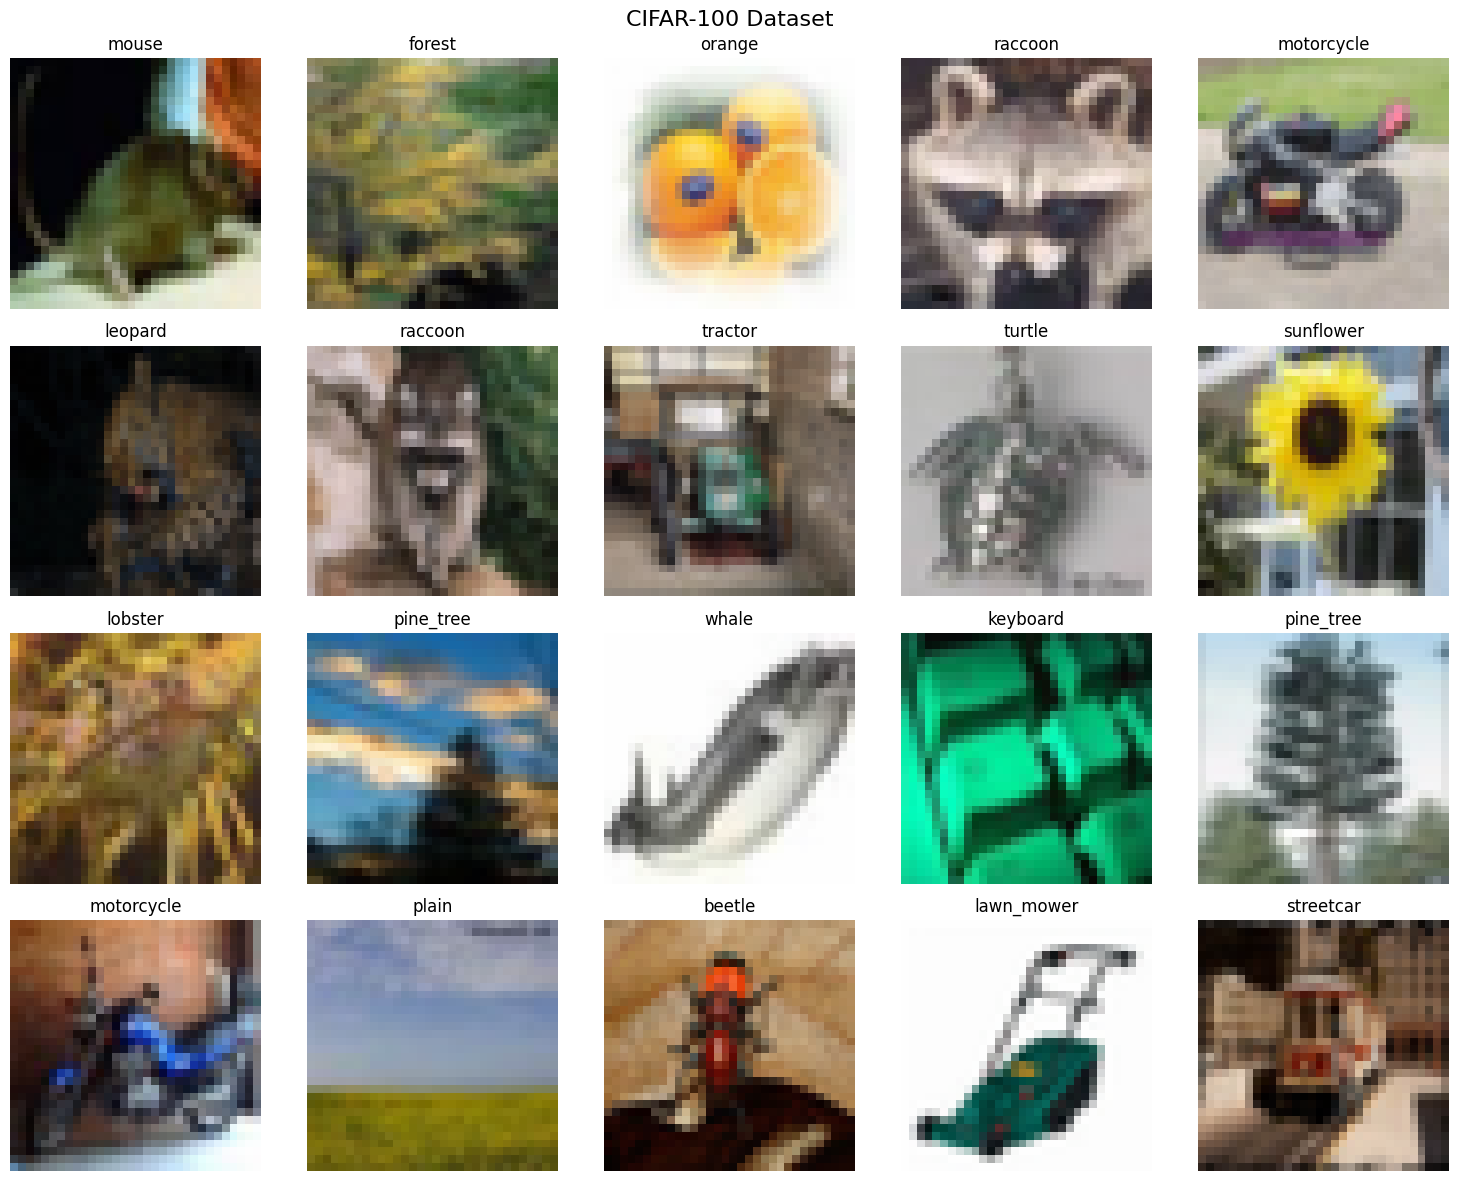

In [45]:
def show_images(dataset, classes, num_images=20):
    indices = random.sample(range(len(dataset)), num_images)

    cols = 5
    rows = (num_images + cols - 1) // cols

    fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 3))
    axes = np.array(axes).reshape(-1)

    mean_np = np.array(mean)
    std_np = np.array(std)

    for i, idx in enumerate(indices):
        image, label = dataset[idx]

        image = image.permute(1, 2, 0).numpy()
        image = image * std_np + mean_np
        image = np.clip(image, 0, 1)

        axes[i].imshow(image)
        axes[i].set_title(classes[label])
        axes[i].axis("off")

    for i in range(num_images, len(axes)):
        axes[i].axis("off")

    plt.suptitle("CIFAR-100 Dataset", fontsize=16)
    plt.tight_layout()
    plt.show()

# Lấy danh sách class từ dataset
classes = test_dataset.classes
show_images(test_dataset, classes)

In [46]:
class VisionTransformer(nn.Module):

    def __init__(
        self,
        image_size=32,
        patch_size=4,
        num_classes=100,
        embed_dim=192,
        depth=6,
        num_heads=6,
        mlp_dim=384,
        dropout=0.1
    ):
        super(VisionTransformer, self).__init__()

        self.patch_size = patch_size

        # Chuyển ảnh thành các patch
        self.patch_embedding = nn.Conv2d(
            in_channels=3,
            out_channels=embed_dim,
            kernel_size=patch_size,
            stride=patch_size
        )

        num_patches = (image_size // patch_size) ** 2

        # Class token
        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, embed_dim)
        )

        # Positional Embedding
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, num_patches + 1, embed_dim)
        )

        self.dropout = nn.Dropout(dropout)

        # Transformer Encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=embed_dim,
            nhead=num_heads,
            dim_feedforward=mlp_dim,
            dropout=dropout,
            activation="gelu",
            batch_first=True,
            norm_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=depth
        )

        self.norm = nn.LayerNorm(embed_dim)

        # Classification Head
        self.head = nn.Linear(embed_dim, num_classes)

        # Khởi tạo tham số
        nn.init.trunc_normal_(self.cls_token, std=0.02)
        nn.init.trunc_normal_(self.pos_embedding, std=0.02)

    def forward(self, x):

        # Bước 1: Patch Embedding
        x = self.patch_embedding(x)

        # [Batch, Embed_dim, 8, 8]
        x = x.flatten(2)

        # [Batch, 64, Embed_dim]
        x = x.transpose(1, 2)

        # Bước 2: Thêm Class Token
        cls_tokens = self.cls_token.expand(x.shape[0], -1, -1)

        x = torch.cat((cls_tokens, x), dim=1)

        # Bước 3: Thêm Positional Embedding
        x = x + self.pos_embedding

        x = self.dropout(x)

        # Bước 4: Transformer Encoder
        x = self.transformer(x)

        # Bước 5: Lấy đặc trưng từ Class Token
        x = self.norm(x[:, 0])

        # Bước 6: Phân loại
        x = self.head(x)

        return x

In [47]:
model = VisionTransformer().to(device)

print(model)

total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Tổng số tham số:", total_params)
print("Số tham số có thể huấn luyện:", trainable_params)

# Kiểm tra kích thước đầu ra
sample = torch.randn(2, 3, 32, 32).to(device)

output = model(sample)

print("Kích thước đầu vào:", sample.shape)
print("Kích thước đầu ra:", output.shape)

VisionTransformer(
  (patch_embedding): Conv2d(3, 192, kernel_size=(4, 4), stride=(4, 4))
  (dropout): Dropout(p=0.1, inplace=False)
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-5): 6 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=192, out_features=192, bias=True)
        )
        (linear1): Linear(in_features=192, out_features=384, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=384, out_features=192, bias=True)
        (norm1): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
        (norm2): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (norm): LayerNorm((192,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=192, out_features=100, bias=True

/tmp/ipykernel_16422/1995245351.py:51: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  self.transformer = nn.TransformerEncoder(


In [52]:
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0005,
    weight_decay=0.05
)

num_epochs = 50

scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=num_epochs,
    eta_min=1e-6
)

train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

best_val_acc = 0.0
best_epoch = 0
patience = 7
counter = 0

In [49]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Xóa gradient cũ
        optimizer.zero_grad()

        # Forward
        outputs = model(images)

        # Tính Loss
        loss = criterion(outputs, labels)

        # Backward
        loss.backward()

        # Cập nhật trọng số
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total
    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [50]:
def evaluate_model(model, test_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()

            all_predictions.extend(
                predicted.cpu().numpy()
            )

            all_labels.extend(
                labels.cpu().numpy()
            )

    test_loss = running_loss / total
    test_accuracy = 100 * correct / total

    return (
        test_loss,
        test_accuracy,
        all_predictions,
        all_labels
    )

In [53]:
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

for epoch in range(num_epochs):

    start_time = time.time()

    # 1. Huấn luyện
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    # 2. Đánh giá Validation
    val_loss, val_acc, _, _ = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    # 3. Điều chỉnh Learning Rate
    scheduler.step()

    # 4. Lưu kết quả
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    # 5. Kiểm tra cải thiện Validation
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_epoch = epoch + 1
        counter = 0

        torch.save(
            model.state_dict(),
            "best_vit_cifar100.pth"
        )

        status = "Saved Best Model"

    else:
        counter += 1
        status = f"Early Stopping: {counter}/{patience}"

    elapsed_time = time.time() - start_time

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"| Train Loss: {train_loss:.4f} "
        f"| Train Acc: {train_acc:.2f}% "
        f"| Val Loss: {val_loss:.4f} "
        f"| Val Acc: {val_acc:.2f}% "
        f"| Best Val: {best_val_acc:.2f}% "
        f"| {status} "
        f"| Time: {elapsed_time:.1f}s"
    )

    # 6. Dừng sớm nếu không cải thiện
    if counter >= patience:
        print("\nEarly Stopping được kích hoạt!")
        print(f"Dừng tại Epoch: {epoch+1}")
        break

print("\nHOÀN THÀNH HUẤN LUYỆN")
print(f"Best Epoch: {best_epoch}")
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")

Epoch [1/50] | Train Loss: 3.6844 | Train Acc: 16.94% | Val Loss: 3.5017 | Val Acc: 20.88% | Best Val: 20.88% | Saved Best Model | Time: 31.3s
Epoch [2/50] | Train Loss: 3.4906 | Train Acc: 20.93% | Val Loss: 3.3824 | Val Acc: 23.38% | Best Val: 23.38% | Saved Best Model | Time: 31.7s
Epoch [3/50] | Train Loss: 3.3591 | Train Acc: 24.08% | Val Loss: 3.2533 | Val Acc: 26.54% | Best Val: 26.54% | Saved Best Model | Time: 30.5s
Epoch [4/50] | Train Loss: 3.2572 | Train Acc: 26.10% | Val Loss: 3.1690 | Val Acc: 28.66% | Best Val: 28.66% | Saved Best Model | Time: 31.2s
Epoch [5/50] | Train Loss: 3.1638 | Train Acc: 28.58% | Val Loss: 3.0886 | Val Acc: 30.16% | Best Val: 30.16% | Saved Best Model | Time: 31.5s
Epoch [6/50] | Train Loss: 3.0789 | Train Acc: 30.54% | Val Loss: 3.0257 | Val Acc: 32.58% | Best Val: 32.58% | Saved Best Model | Time: 30.7s
Epoch [7/50] | Train Loss: 3.0116 | Train Acc: 32.12% | Val Loss: 2.9228 | Val Acc: 34.74% | Best Val: 34.74% | Saved Best Model | Time: 30.6s

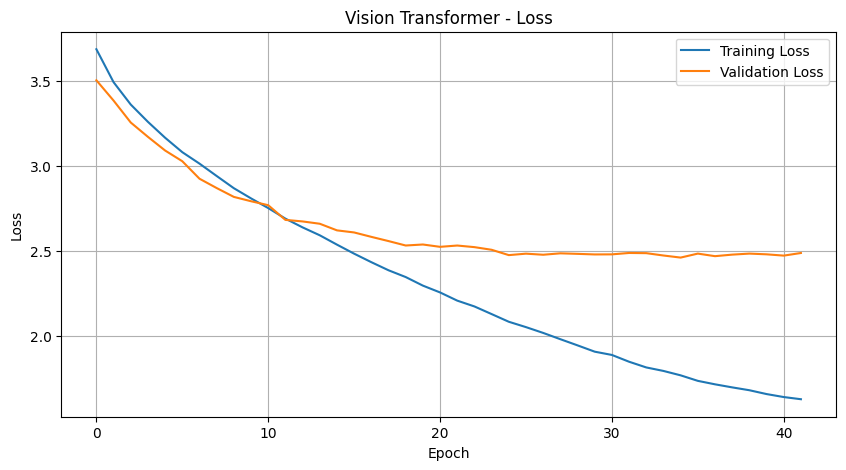

In [54]:
plt.figure(figsize=(10, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.title("Vision Transformer - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)
plt.show()

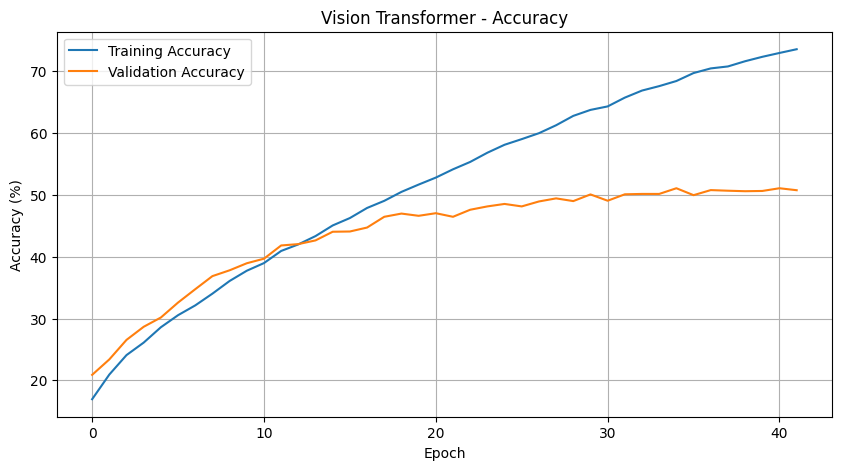

In [55]:
plt.figure(figsize=(10, 5))

plt.plot(train_accuracies, label="Training Accuracy")
plt.plot(val_accuracies, label="Validation Accuracy")

plt.title("Vision Transformer - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True)
plt.show()

In [56]:
val_loss, val_acc, _, _ = evaluate_model(
    model,
    val_loader,
    criterion,
    device
)

print(
    f"Validation Loss: {val_loss:.4f} "
    f"| Validation Accuracy: {val_acc:.2f}%"
)

Validation Loss: 2.4859 | Validation Accuracy: 50.76%


In [57]:
best_val_acc = max(val_accuracies)
best_epoch = val_accuracies.index(best_val_acc) + 1

print("===== KẾT QUẢ HUẤN LUYỆN ViT =====")
print(f"Số Epoch: {num_epochs}")
print(f"Training Accuracy cuối: {train_accuracies[-1]:.2f}%")
print(f"Validation Accuracy cuối: {val_accuracies[-1]:.2f}%")
print(f"Validation Loss cuối: {val_losses[-1]:.4f}")
print(f"Validation Accuracy cao nhất: {best_val_acc:.2f}%")
print(f"Đạt tại Epoch: {best_epoch}")

===== KẾT QUẢ HUẤN LUYỆN ViT =====
Số Epoch: 50
Training Accuracy cuối: 73.58%
Validation Accuracy cuối: 50.76%
Validation Loss cuối: 2.4859
Validation Accuracy cao nhất: 51.08%
Đạt tại Epoch: 35


In [58]:
# Tải trọng số tốt nhất theo Validation
model.load_state_dict(
    torch.load(
        "best_vit_cifar100.pth",
        map_location=device,
        weights_only=True
    )
)

model.eval()

# Đánh giá trên tập Testing
test_loss, test_acc, all_predictions, all_labels = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

print("===== FINAL TEST RESULTS =====")
print("Best Epoch:", best_epoch)
print(f"Best Validation Accuracy: {best_val_acc:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.2f}%")

===== FINAL TEST RESULTS =====
Best Epoch: 35
Best Validation Accuracy: 51.08%
Test Loss: 2.4464
Test Accuracy: 51.48%


In [59]:
test_loss, test_acc, all_predictions, all_labels = evaluate_model(
    model,
    test_loader,
    criterion,
    device
)

report = classification_report(
    all_labels,
    all_predictions,
    target_names=classes,
    digits=4,
    zero_division=0
)

print(report)

               precision    recall  f1-score   support

        apple     0.7917    0.7600    0.7755       100
aquarium_fish     0.6500    0.6500    0.6500       100
         baby     0.4906    0.5200    0.5049       100
         bear     0.4265    0.2900    0.3452       100
       beaver     0.3696    0.3400    0.3542       100
          bed     0.3246    0.3700    0.3458       100
          bee     0.6100    0.6100    0.6100       100
       beetle     0.5888    0.6300    0.6087       100
      bicycle     0.5225    0.5800    0.5498       100
       bottle     0.5534    0.5700    0.5616       100
         bowl     0.2687    0.1800    0.2156       100
          boy     0.3896    0.3000    0.3390       100
       bridge     0.5676    0.6300    0.5972       100
          bus     0.4078    0.4200    0.4138       100
    butterfly     0.4231    0.4400    0.4314       100
        camel     0.4153    0.4900    0.4495       100
          can     0.5667    0.5100    0.5368       100
       ca

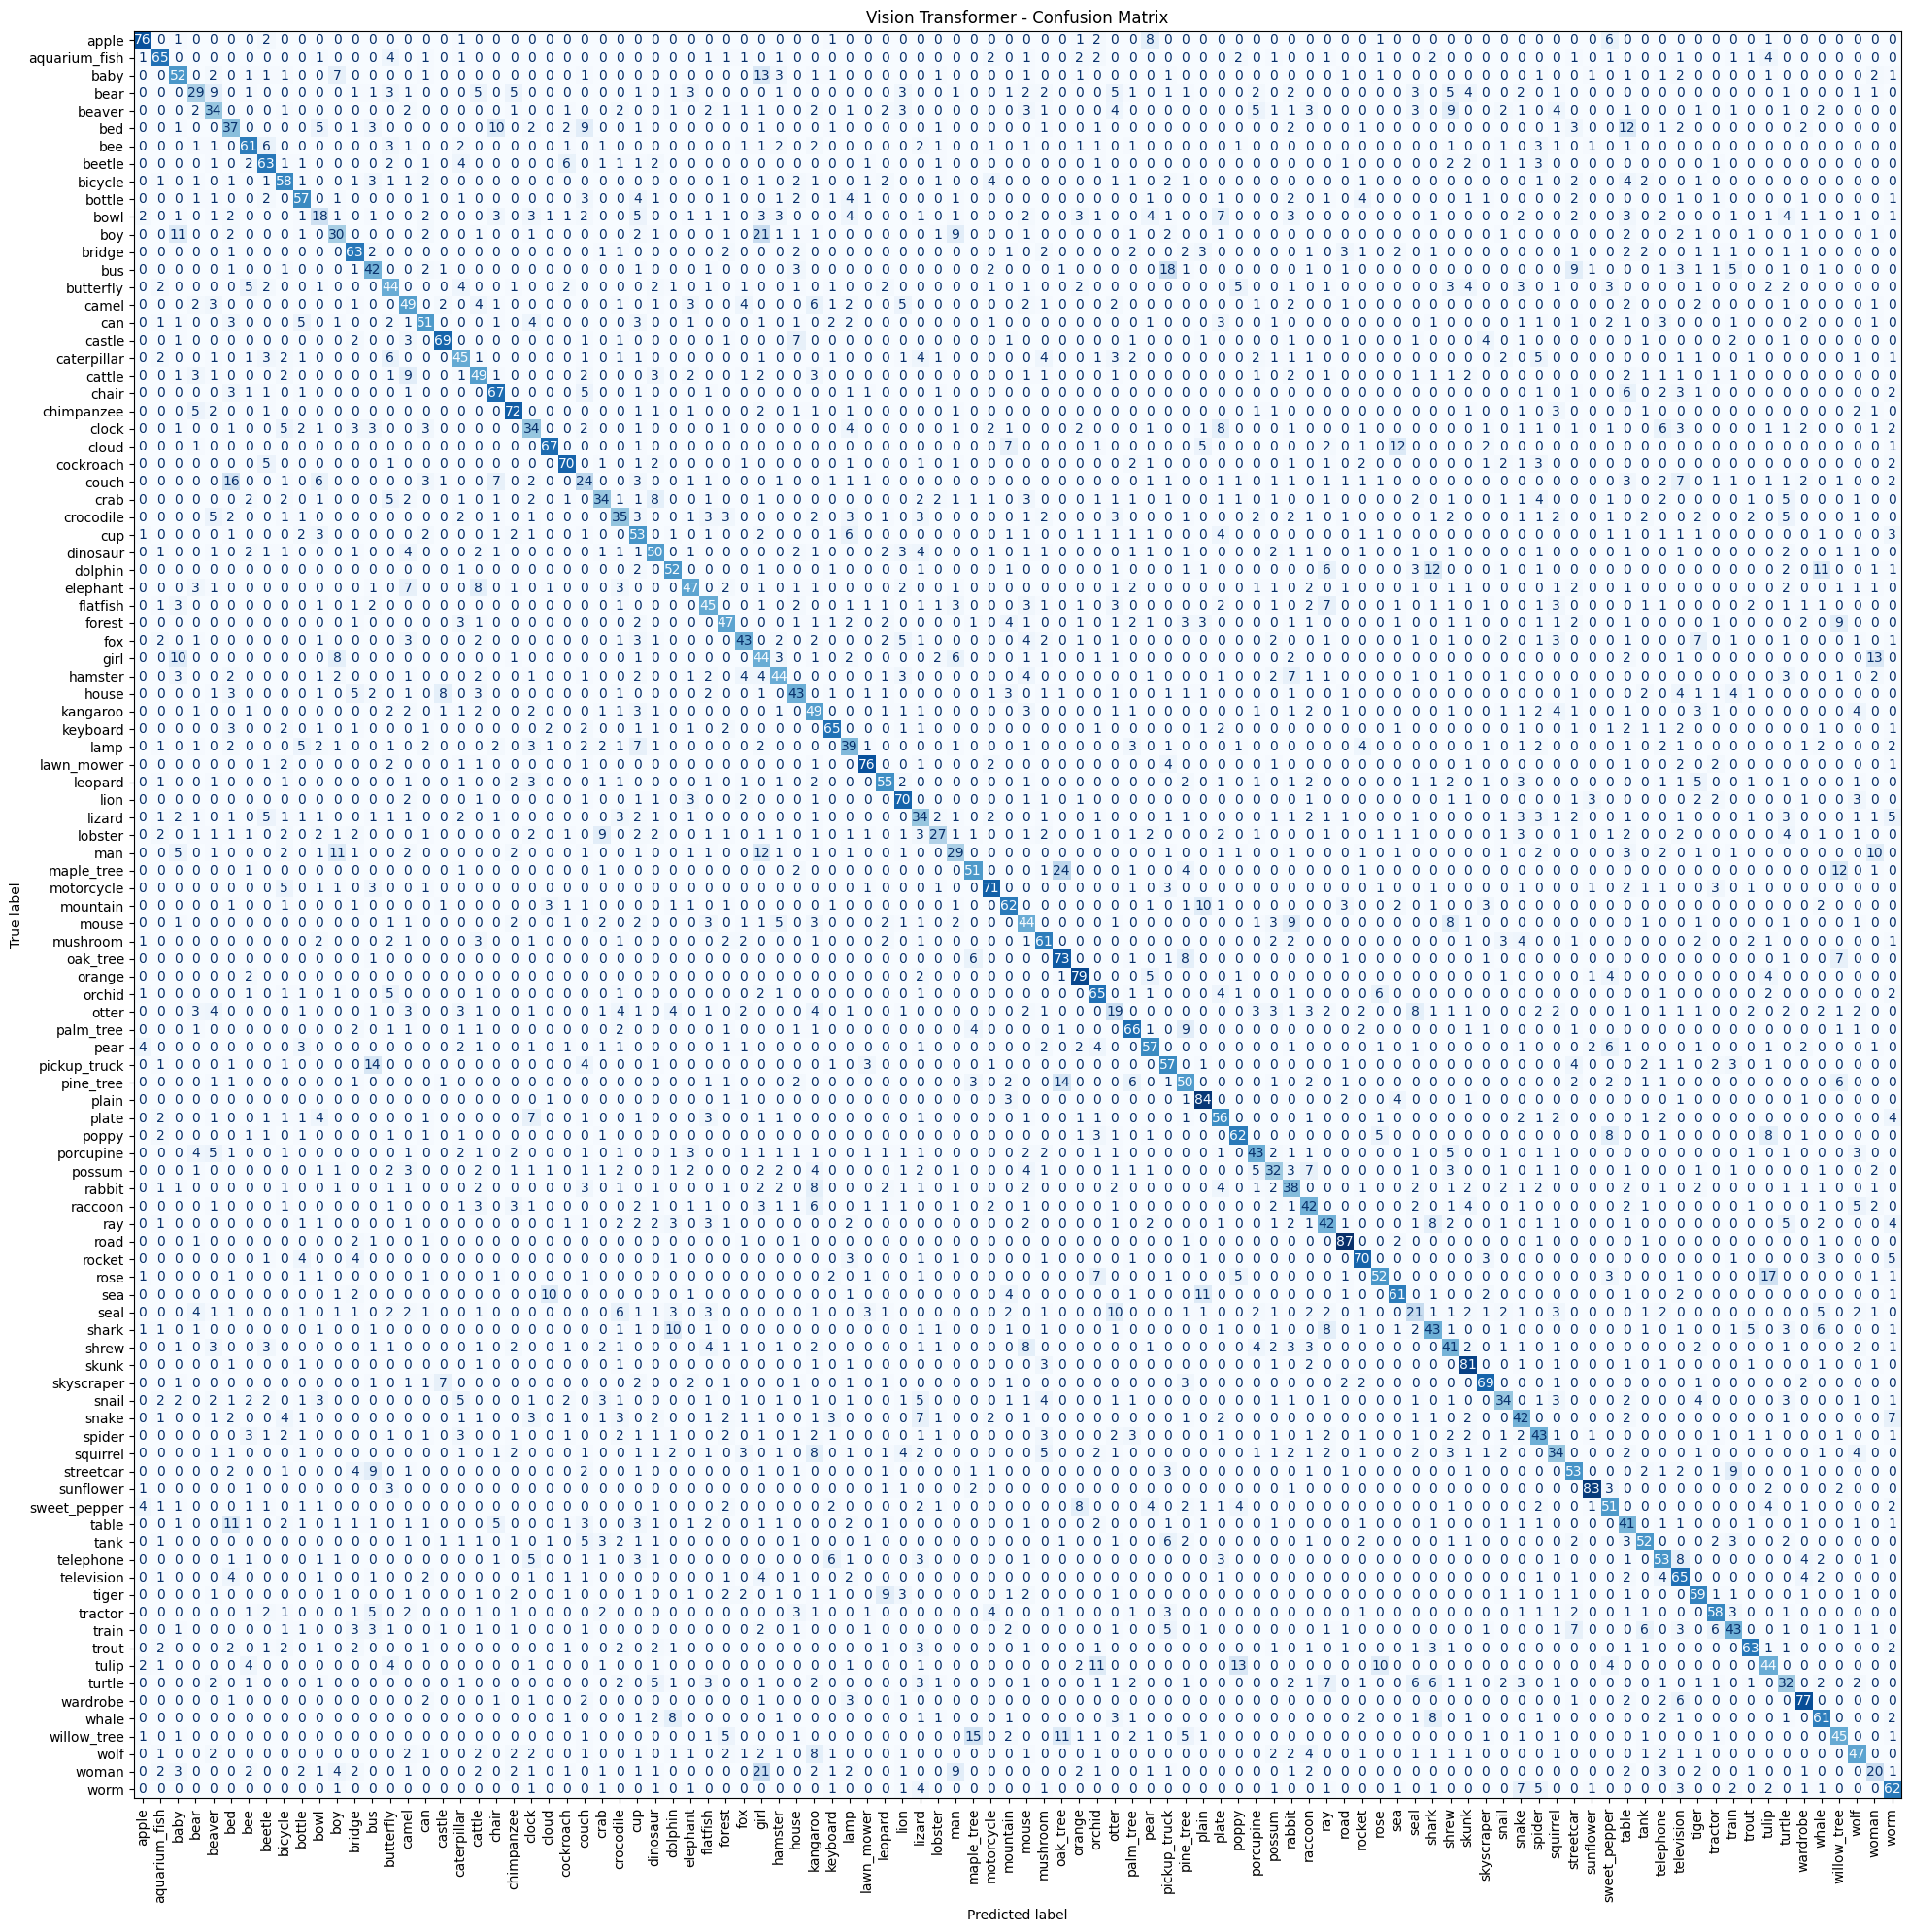

In [60]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)

fig, ax = plt.subplots(figsize=(20, 20))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False,
    values_format="d"
)

plt.title("Vision Transformer - Confusion Matrix")
plt.tight_layout()
plt.show()

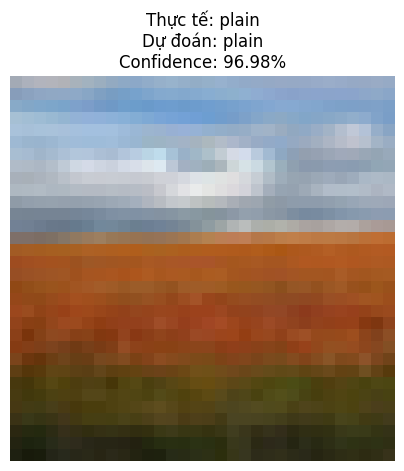

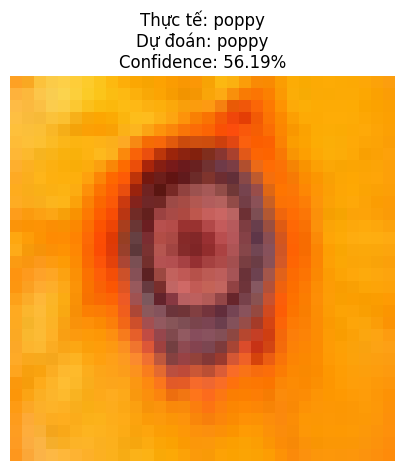

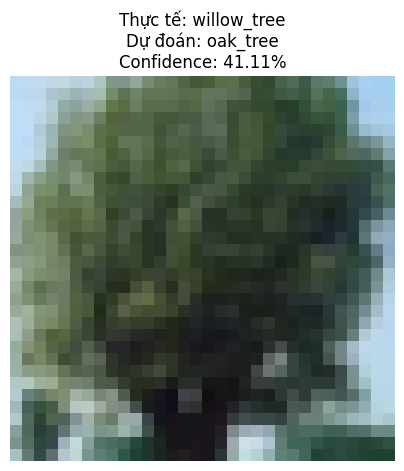

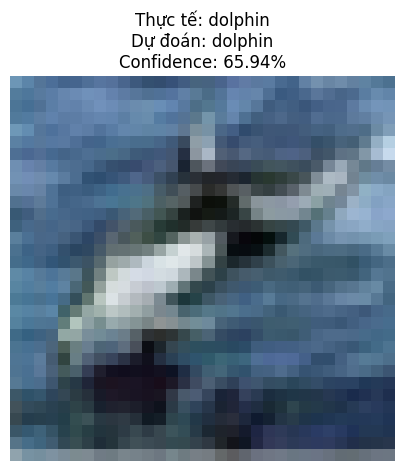

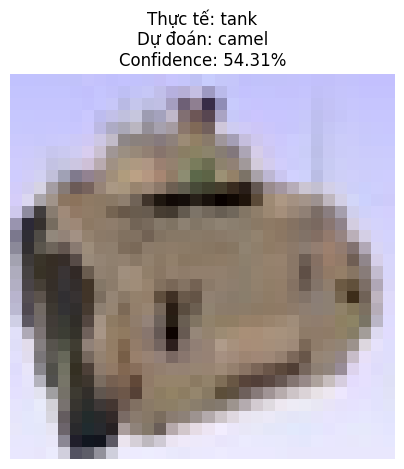

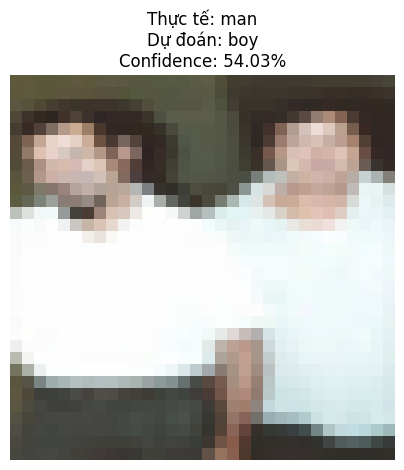

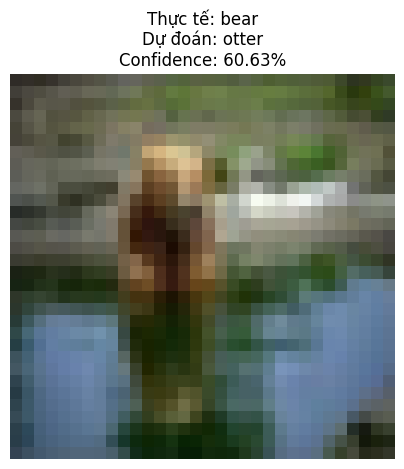

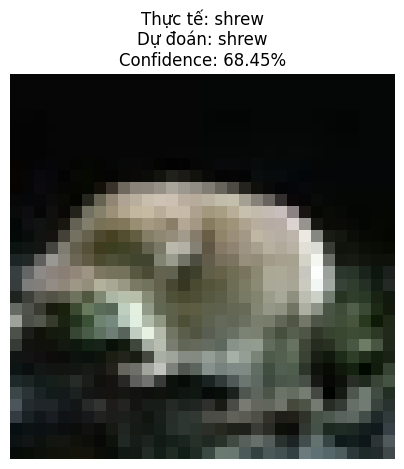

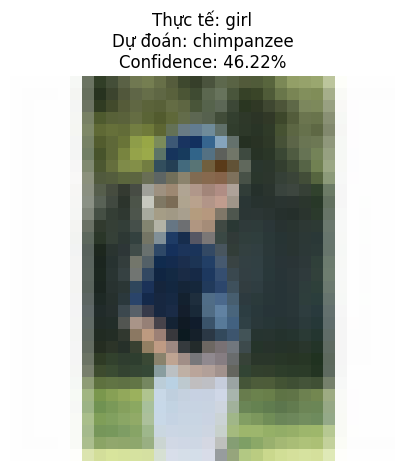

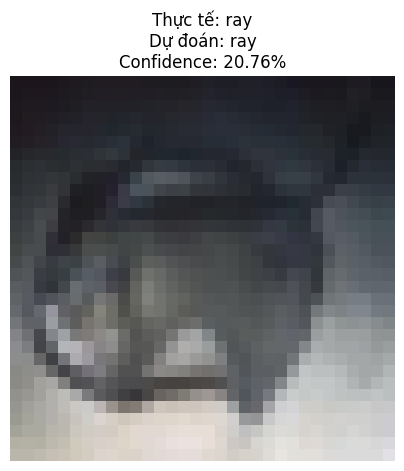

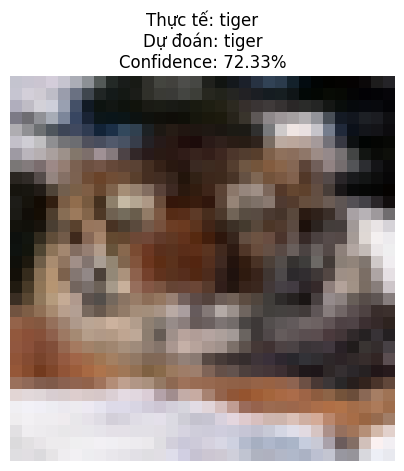

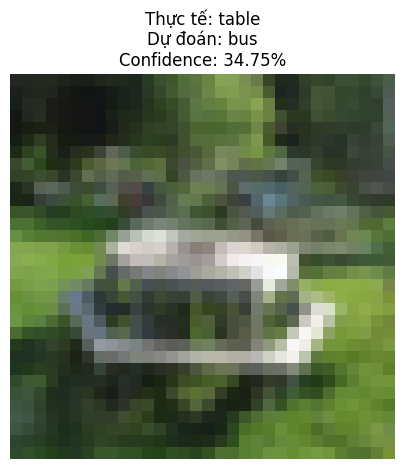

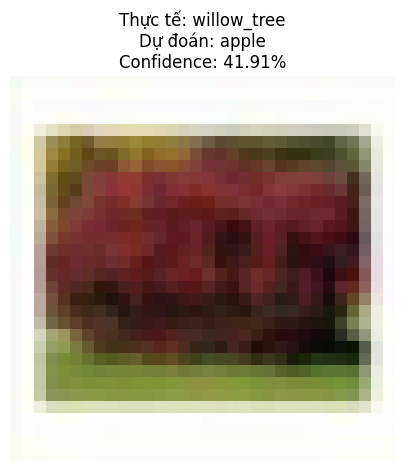

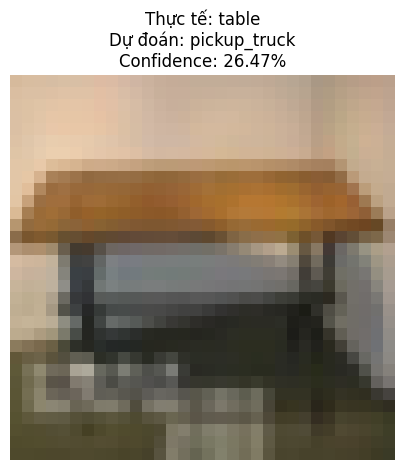

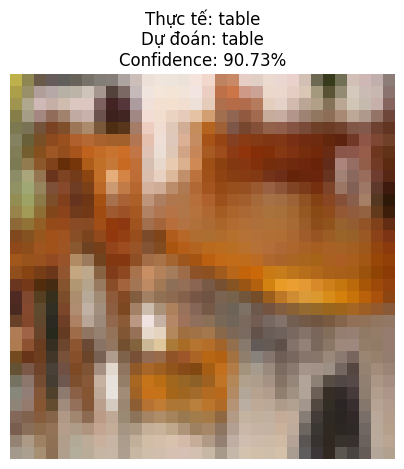

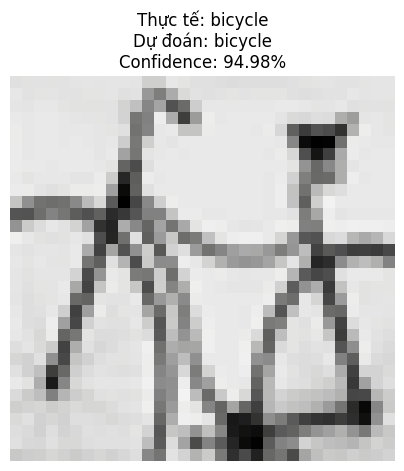

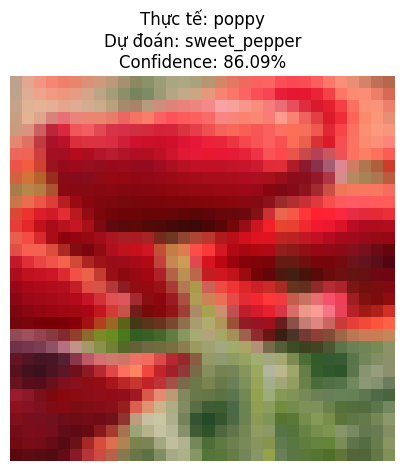

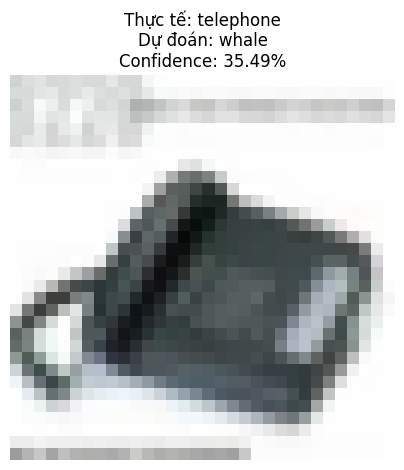

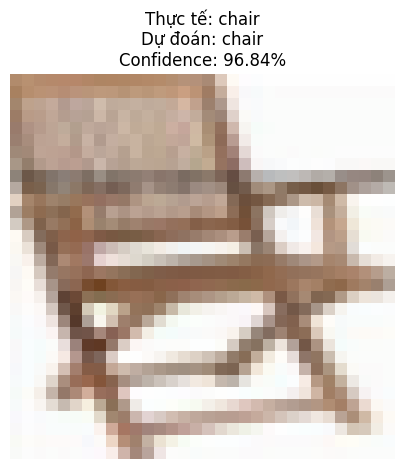

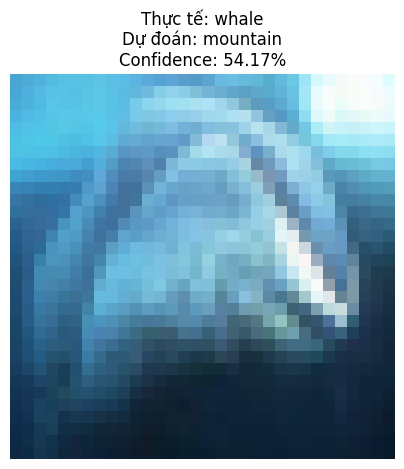

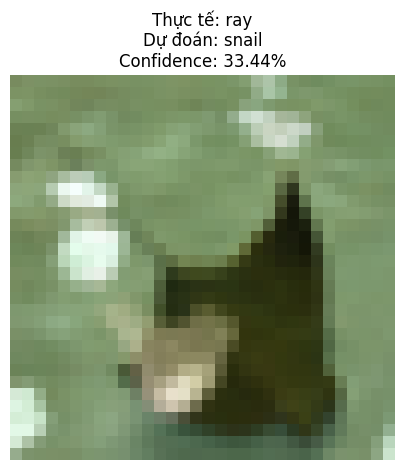

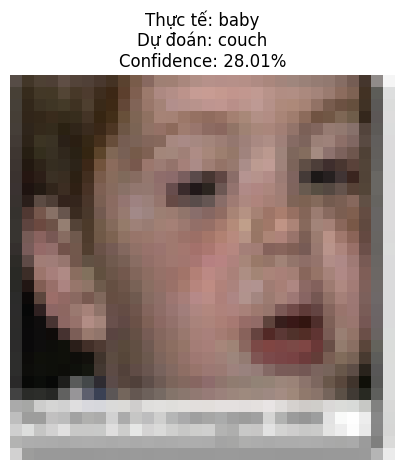

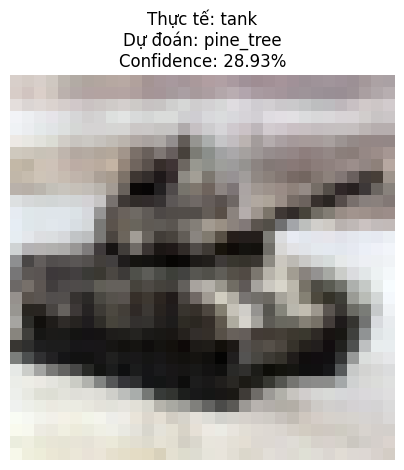

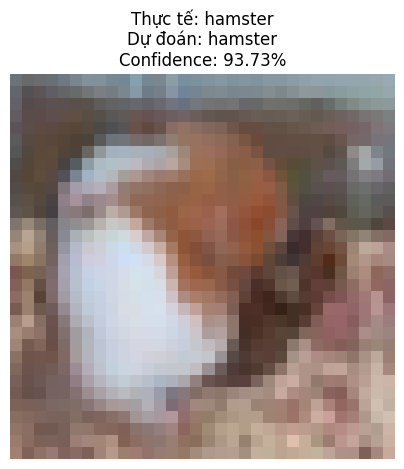

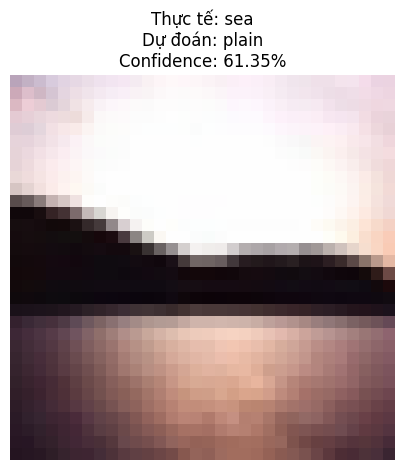

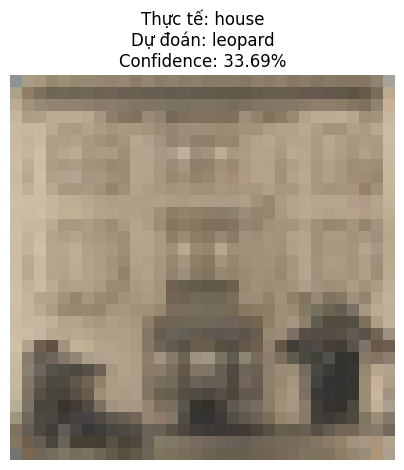

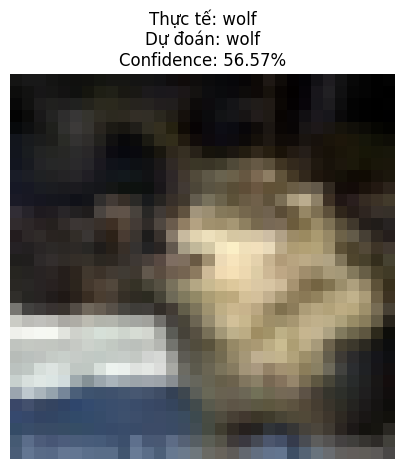

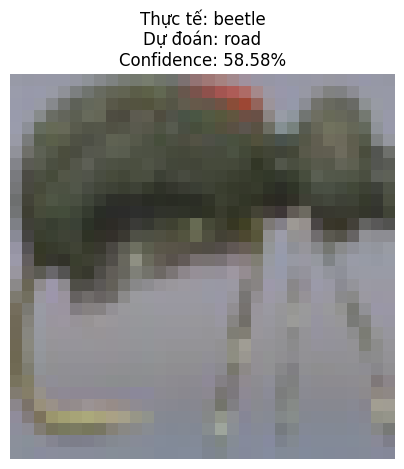

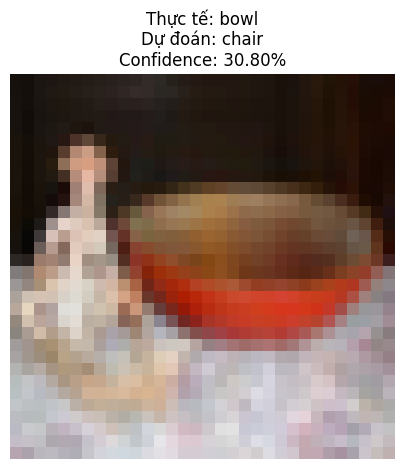

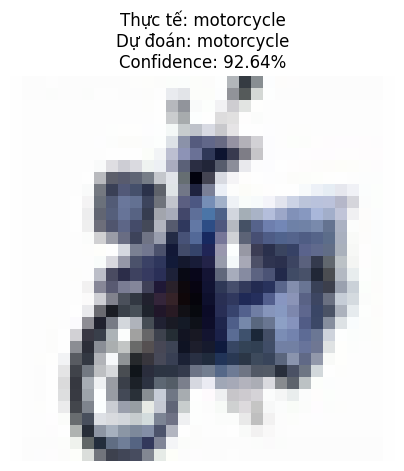

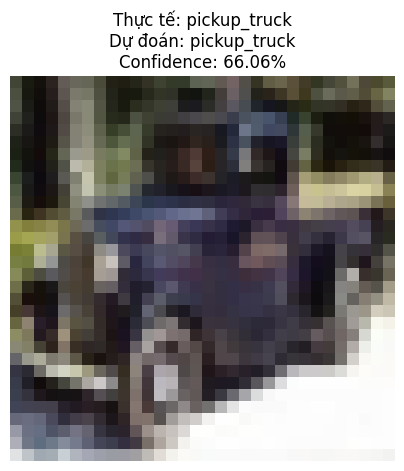

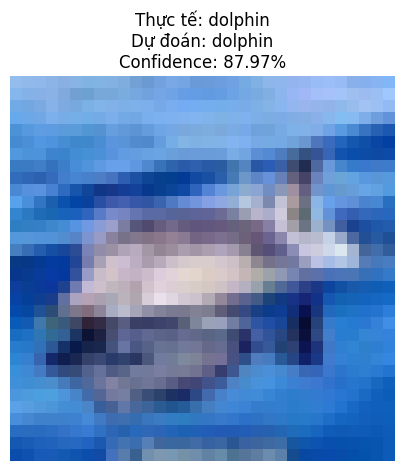

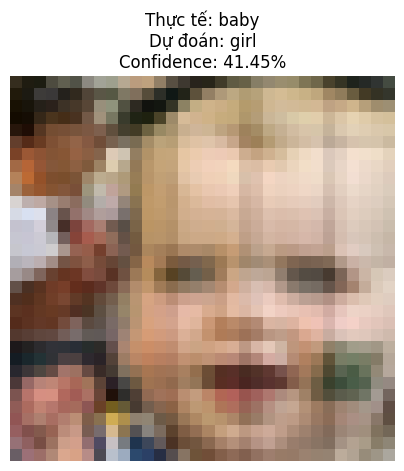

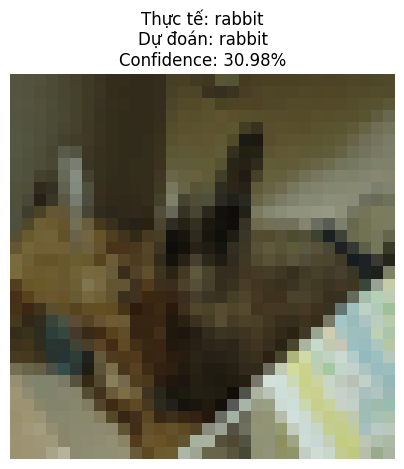

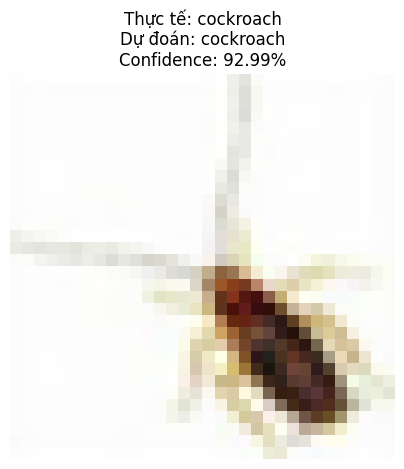

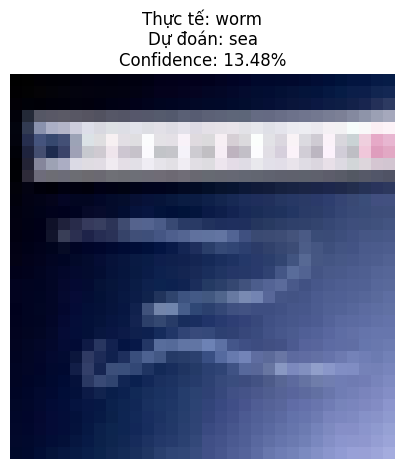

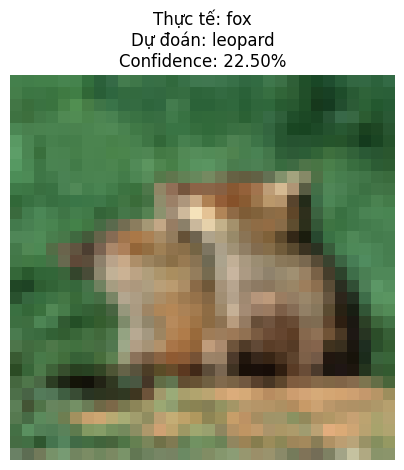

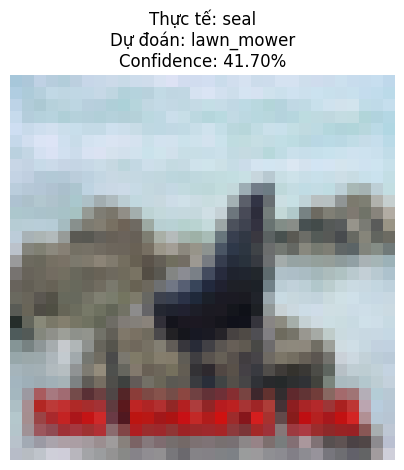

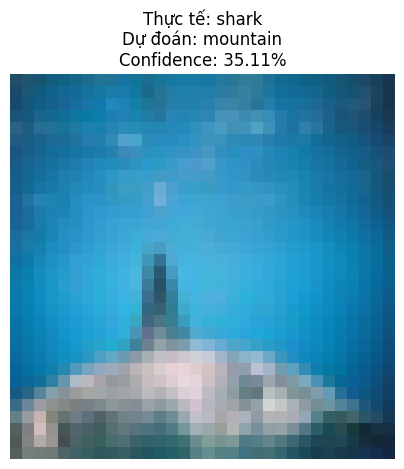

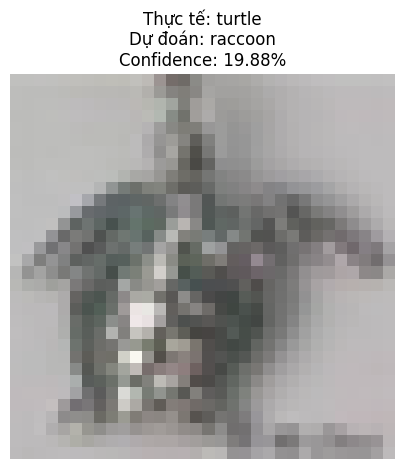

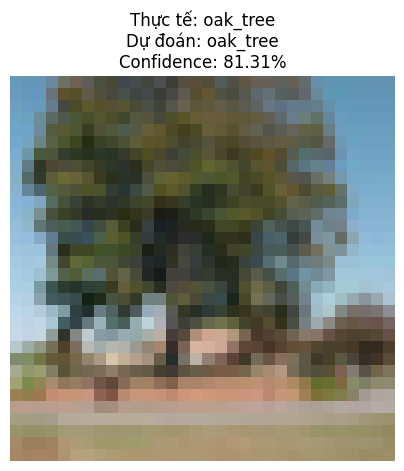

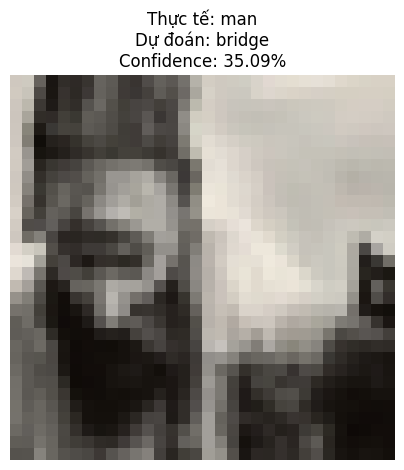

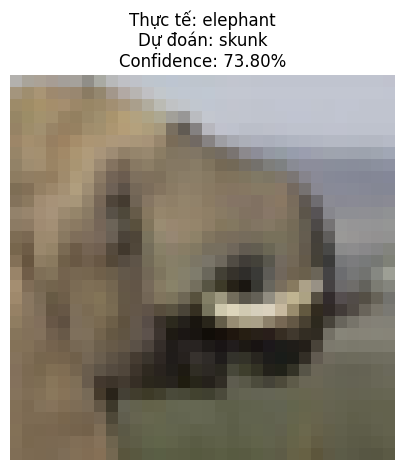

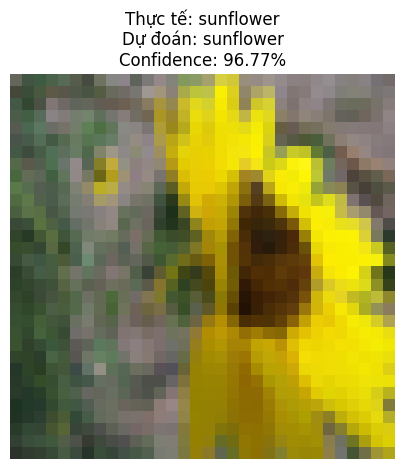

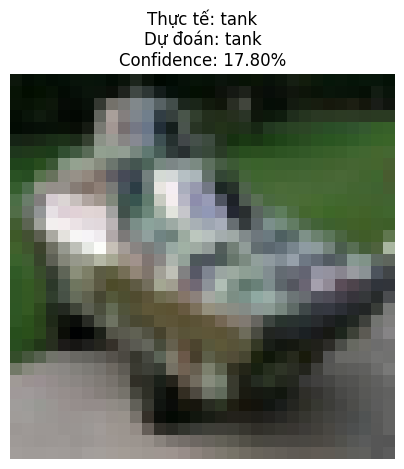

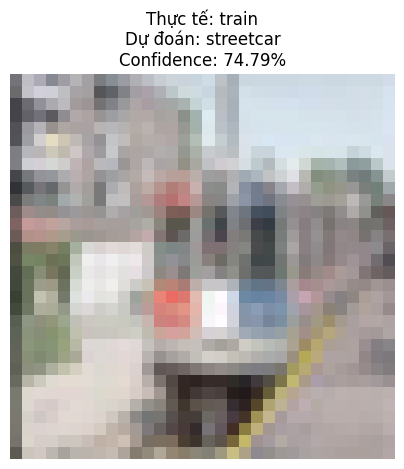

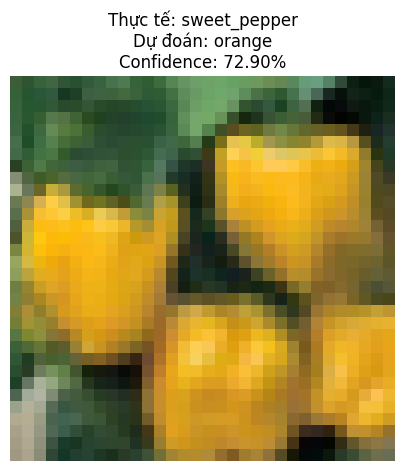

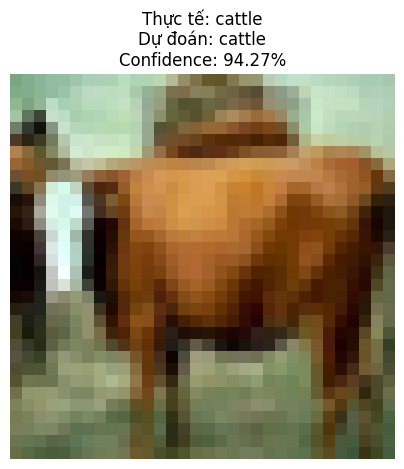

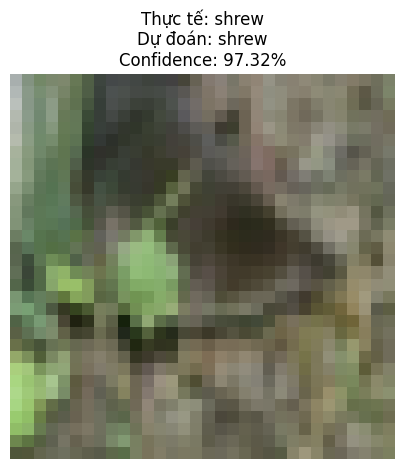

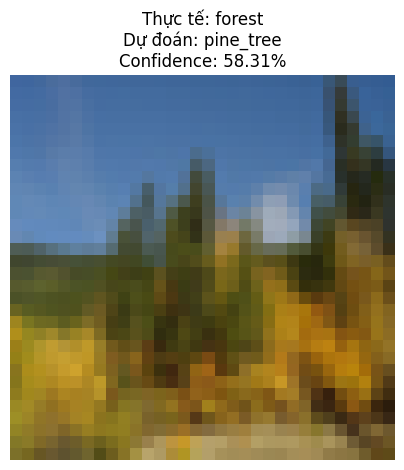

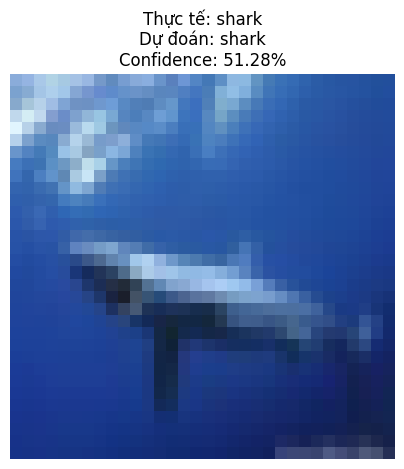

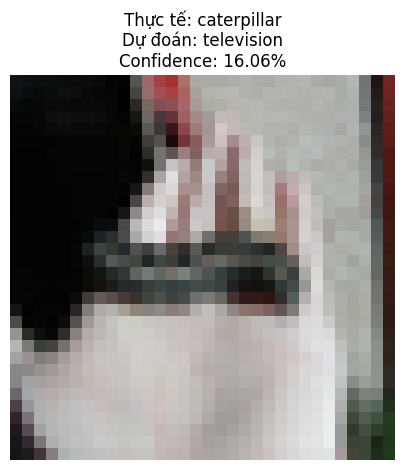

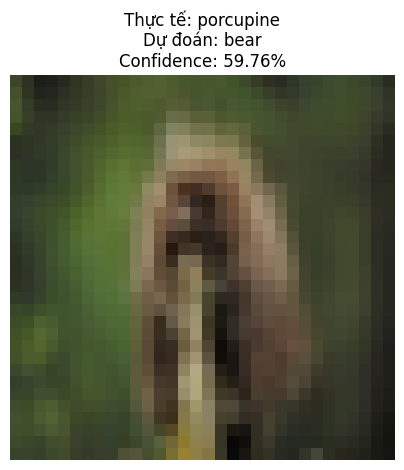

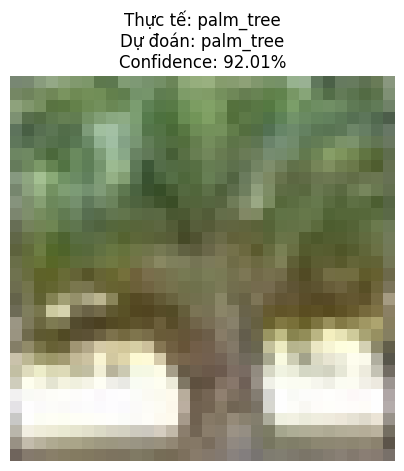

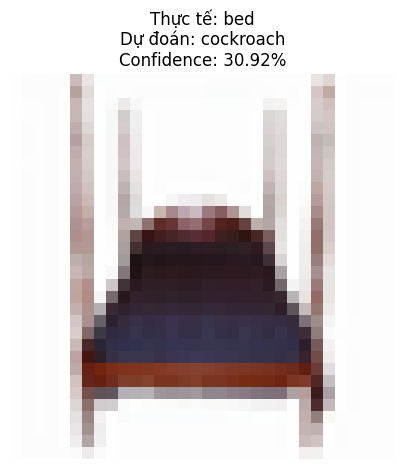

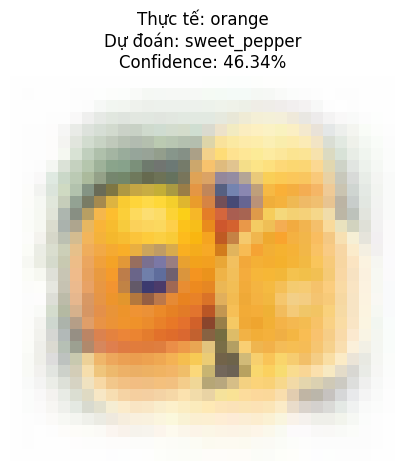

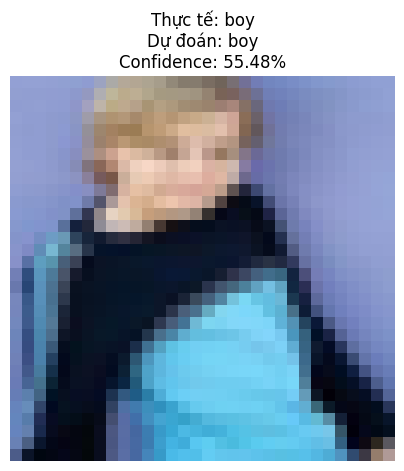

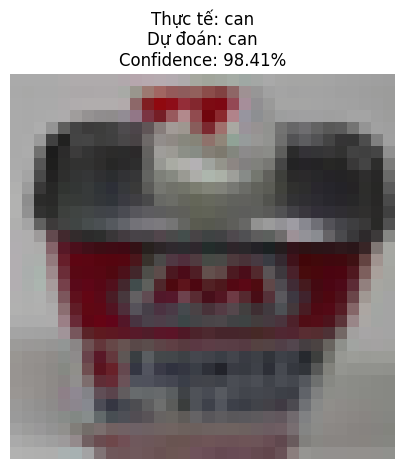

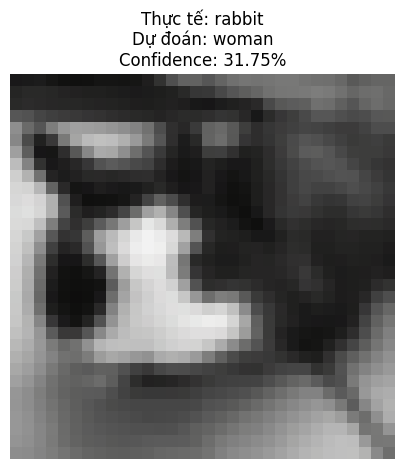

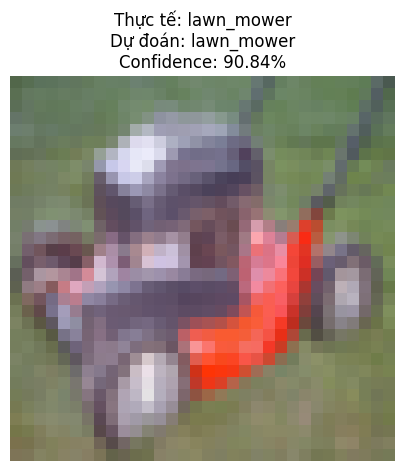

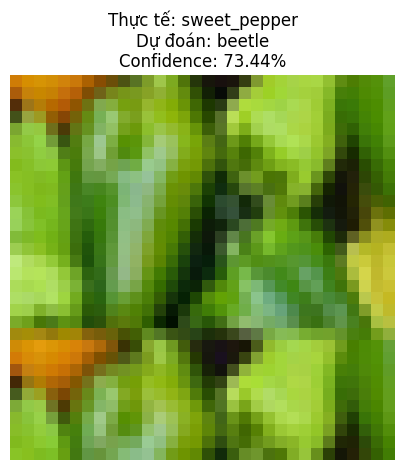

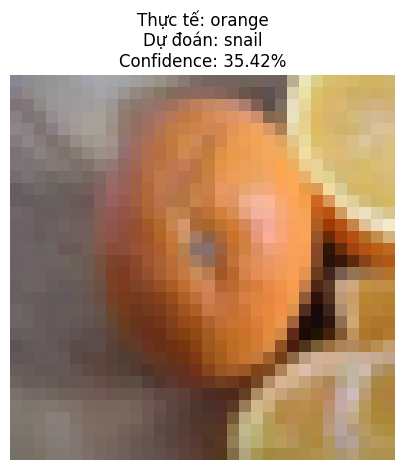

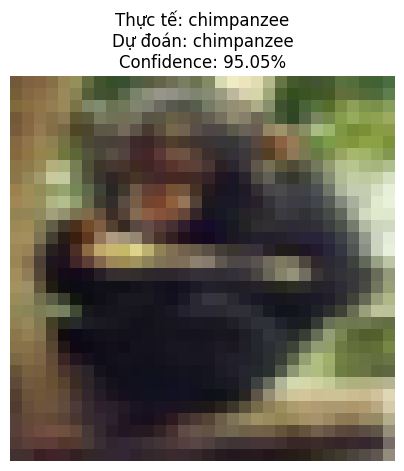

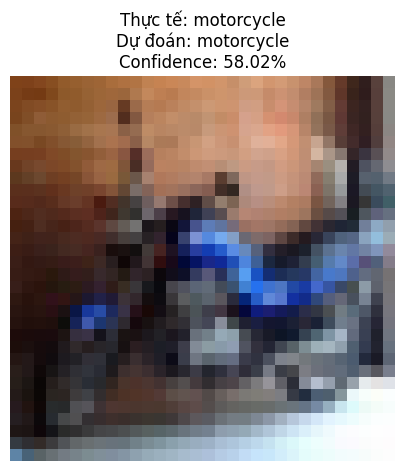

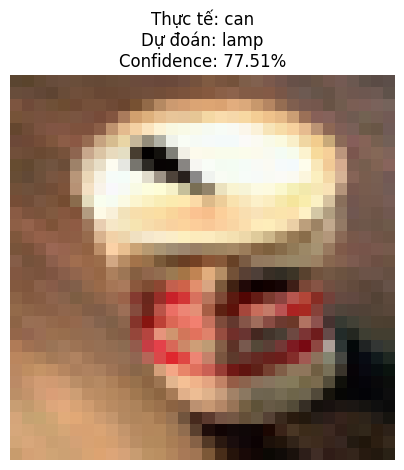

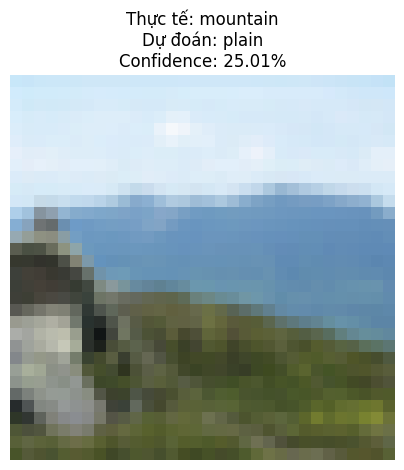

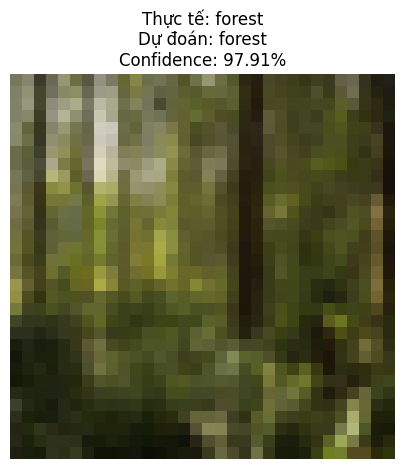

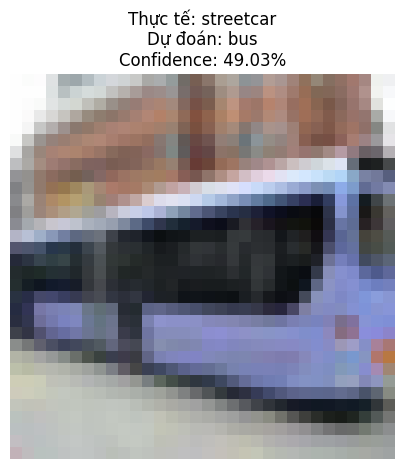

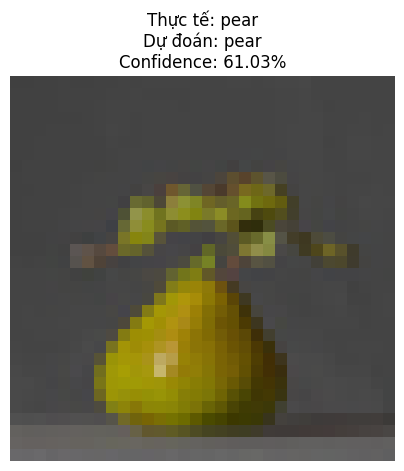

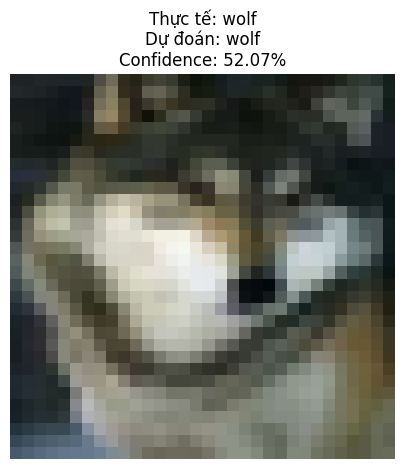

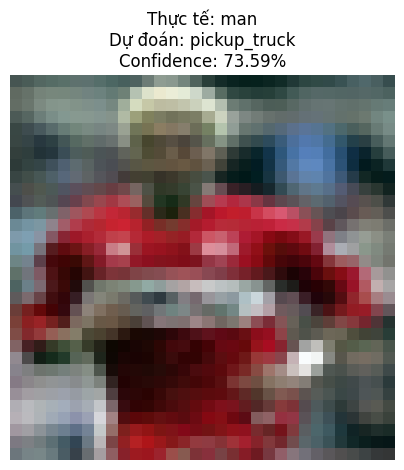

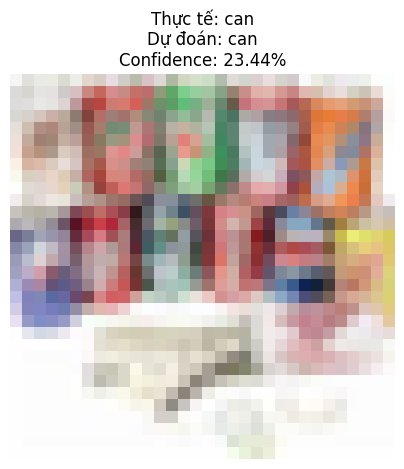

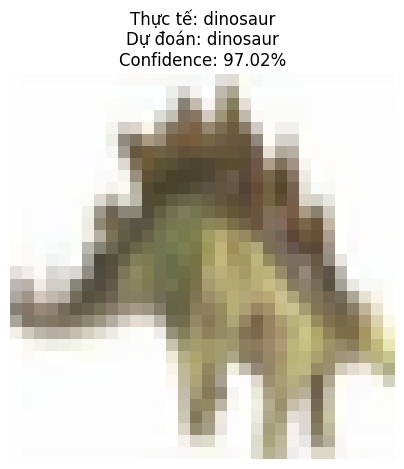

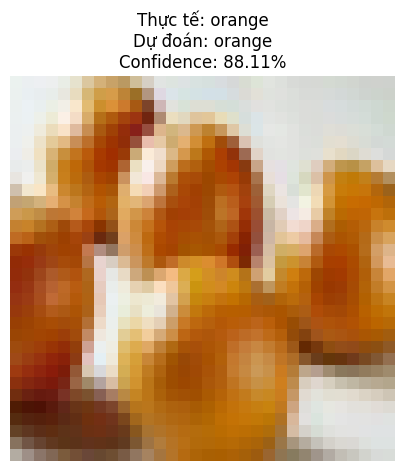

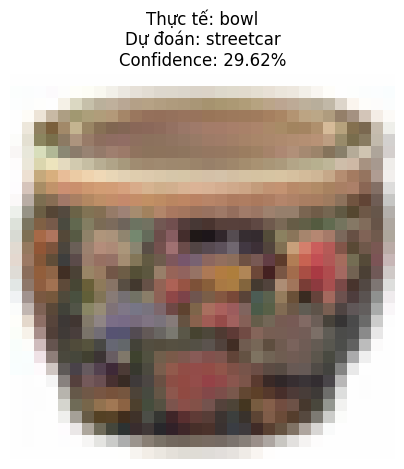

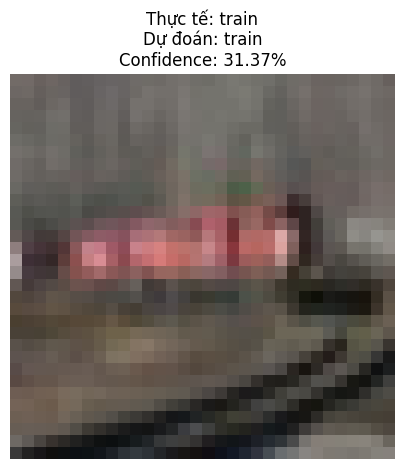

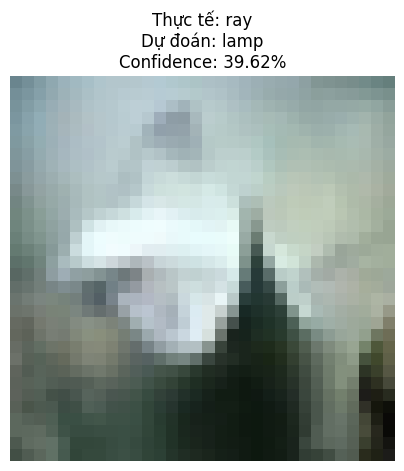

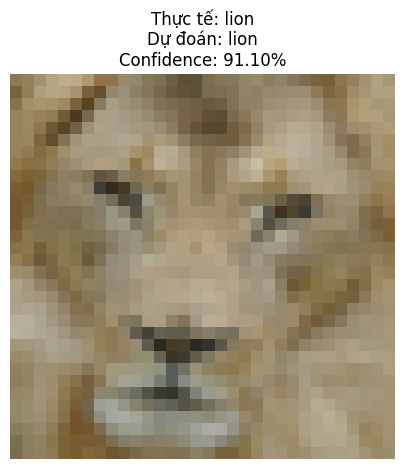

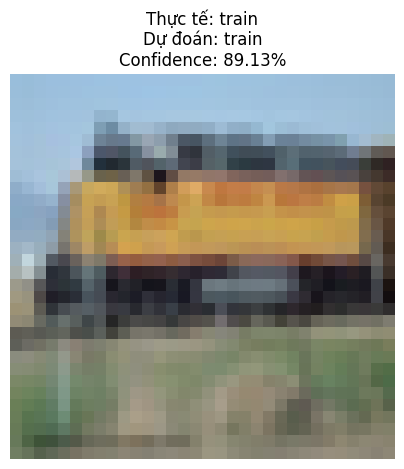

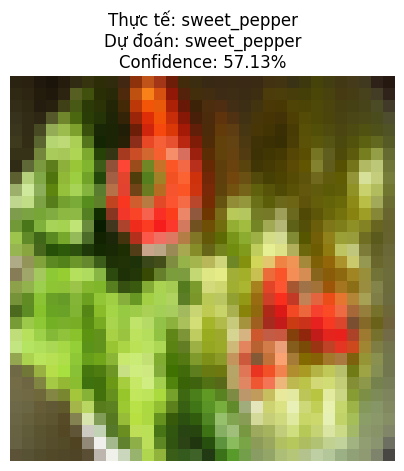

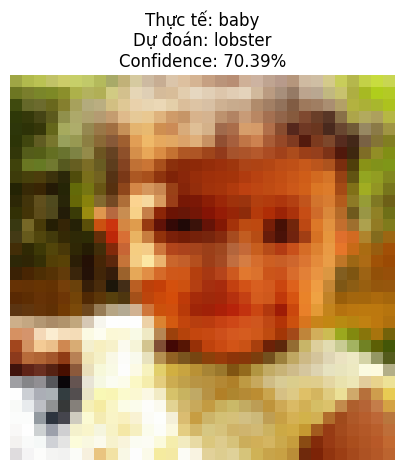

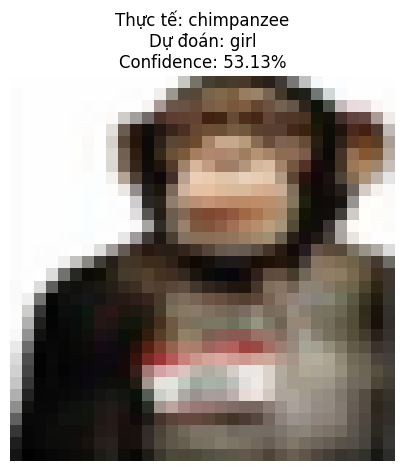

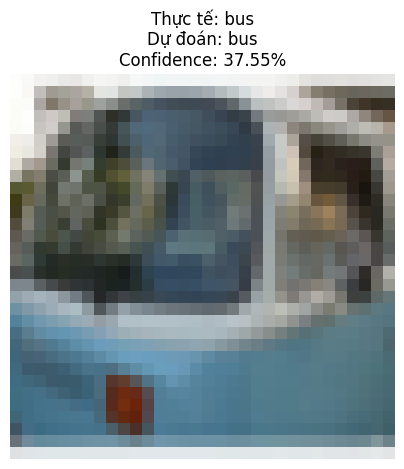

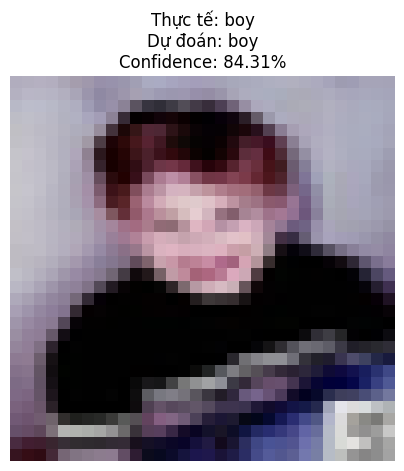

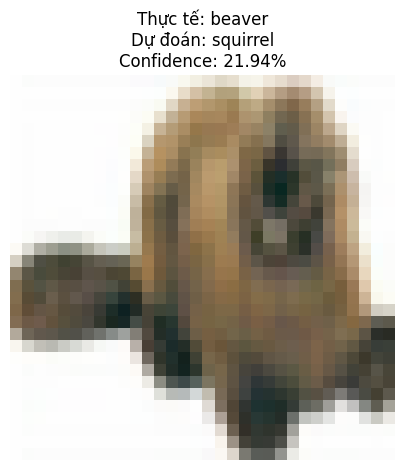

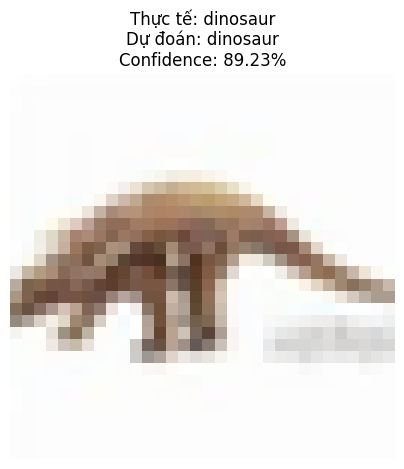

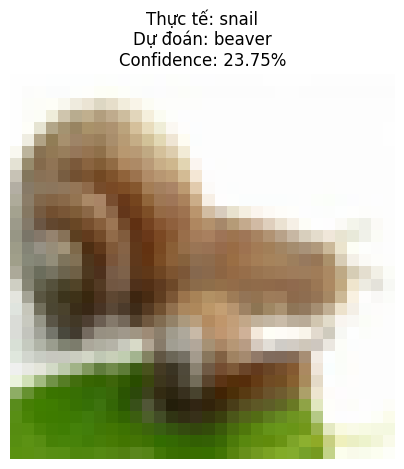

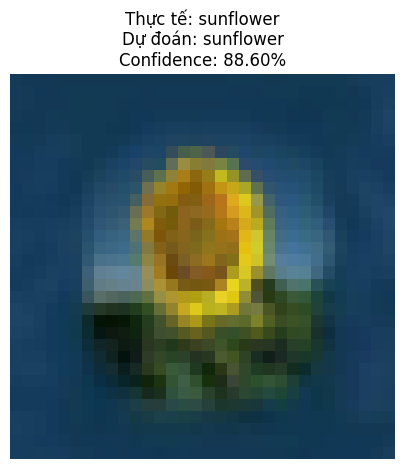

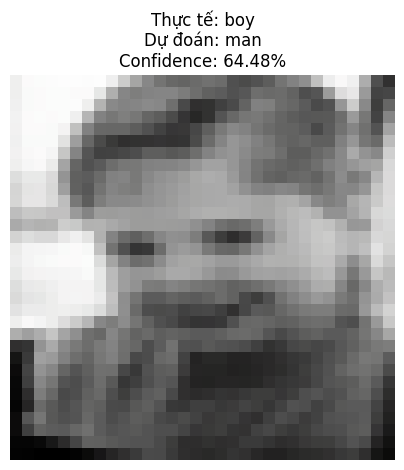

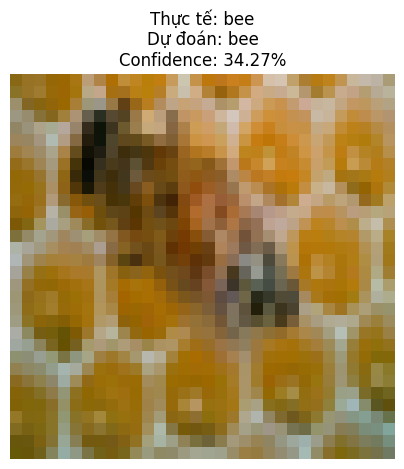

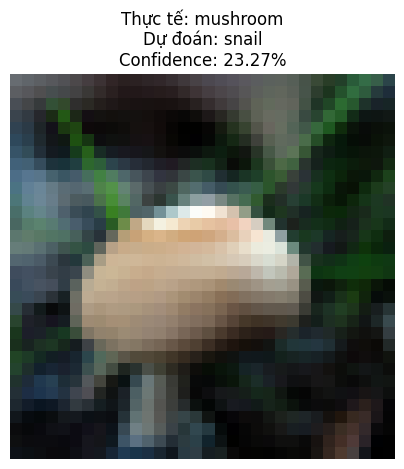

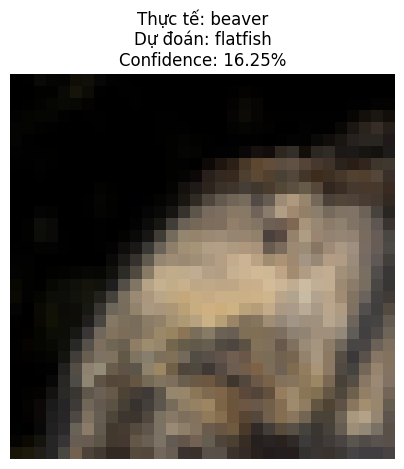

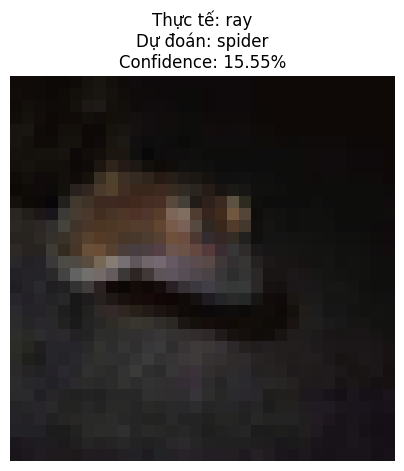

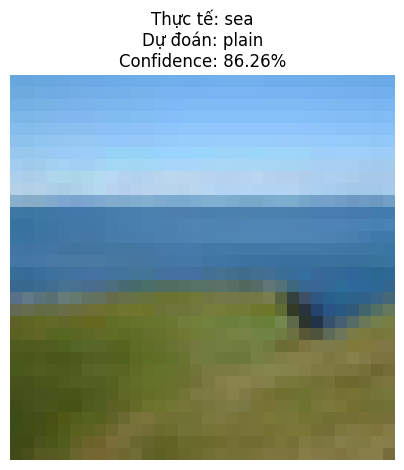

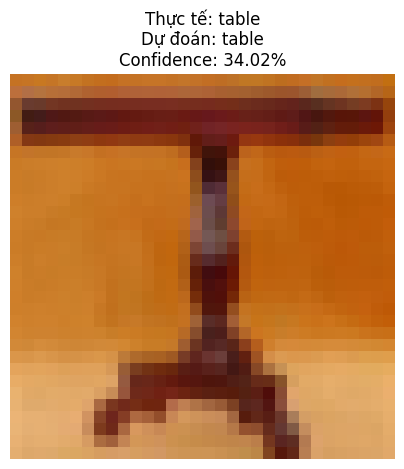

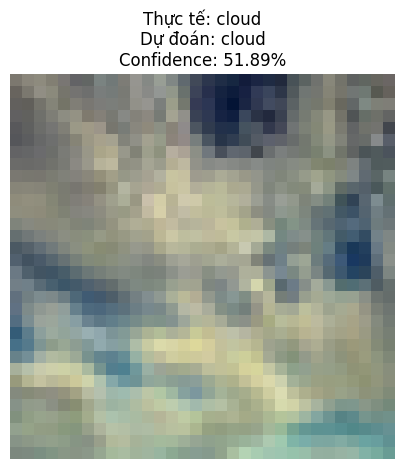

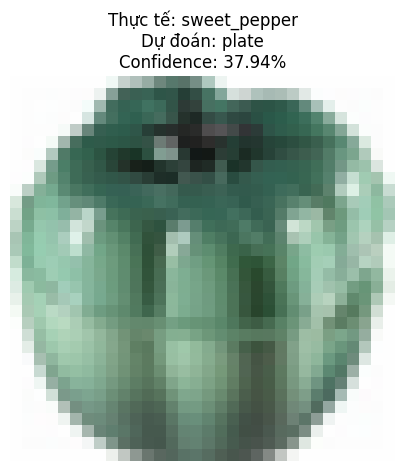

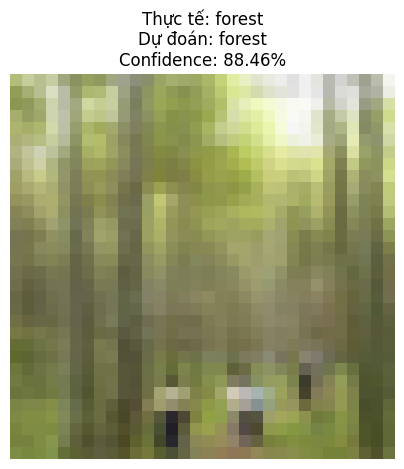

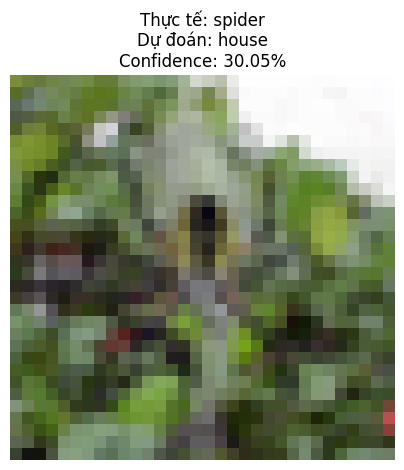

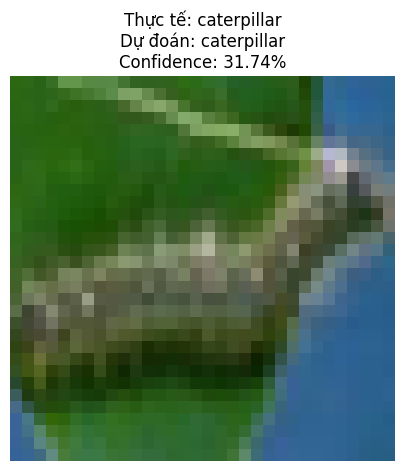

In [61]:
def predict_image(model, dataset, index, classes, device):

    model.eval()

    image, true_label = dataset[index]

    input_image = image.unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_image)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(probabilities, 1)

    predicted_label = predicted.item()

    # Khôi phục ảnh để hiển thị
    image_np = image.permute(1, 2, 0).numpy()

    image_np = image_np * np.array(std) + np.array(mean)
    image_np = np.clip(image_np, 0, 1)

    plt.figure(figsize=(5, 5))
    plt.imshow(image_np)
    plt.axis("off")

    plt.title(
        f"Thực tế: {classes[true_label]}\n"
        f"Dự đoán: {classes[predicted_label]}\n"
        f"Confidence: {confidence.item() * 100:.2f}%"
    )

    plt.show()


# Thử nghiệm với 10 ảnh
for i in random.sample(range(len(test_dataset)), 100):
    predict_image(model, test_dataset, i, classes, device)

Saving Lion_(Panthera_leo)_male_6y.jpg to Lion_(Panthera_leo)_male_6y.jpg


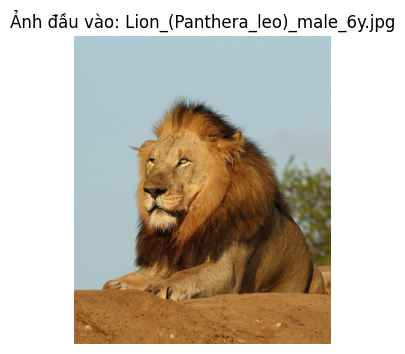


KẾT QUẢ DỰ ĐOÁN: Lion_(Panthera_leo)_male_6y.jpg
---------------------------------------------
Top 1: lion                 | Xác suất: 46.68%
Top 2: camel                | Xác suất: 24.06%
Top 3: tractor              | Xác suất: 10.40%
Top 4: cattle               | Xác suất: 3.07%
Top 5: train                | Xác suất: 1.33%
---------------------------------------------


In [62]:

from google.colab import files
from PIL import Image
import torch
import matplotlib.pyplot as plt
import torchvision.transforms as transforms

# 1. Tải mô hình tốt nhất đã lưu
model.load_state_dict(
    torch.load(
        "best_vit_cifar100.pth",
        map_location=device,
        weights_only=True
    )
)
model.eval()

# 2. Danh sách 100 nhãn CIFAR-100
class_names = test_dataset.classes

# 3. Tải ảnh từ máy tính
uploaded = files.upload()

# 4. Tiền xử lý ảnh
predict_transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5071, 0.4867, 0.4408),
        std=(0.2675, 0.2565, 0.2761)
    )
])

# 5. Dự đoán từng ảnh được tải lên
for filename in uploaded.keys():

    image = Image.open(filename).convert("RGB")

    # Hiển thị ảnh gốc
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.title(f"Ảnh đầu vào: {filename}")
    plt.axis("off")
    plt.show()

    # Chuyển ảnh thành Tensor
    input_tensor = predict_transform(image).unsqueeze(0).to(device)

    # Dự đoán
    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)

        # Lấy Top 5 nhãn có xác suất cao nhất
        top_probs, top_indices = torch.topk(
            probabilities,
            k=5,
            dim=1
        )

    print(f"\nKẾT QUẢ DỰ ĐOÁN: {filename}")
    print("-" * 45)

    for i in range(5):
        class_index = top_indices[0][i].item()
        confidence = top_probs[0][i].item() * 100

        print(
            f"Top {i+1}: {class_names[class_index]:<20}"
            f" | Xác suất: {confidence:.2f}%"
        )

    print("-" * 45)
